In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import scipy.optimize as opt
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')
import os
os.chdir("/Users/lleid/Downloads")
data = pd.read_csv("recursos_humanos (1).csv")
data

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low
...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,support,low
14995,0.37,0.48,2,160,3,0,1,0,support,low
14996,0.37,0.53,2,143,3,0,1,0,support,low
14997,0.11,0.96,6,280,4,0,1,0,support,low


In [2]:
data = pd.get_dummies(data, columns=["sales", "salary"], dtype=int)
data

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales_IT,sales_RandD,...,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_high,salary_low,salary_medium
0,0.38,0.53,2,157,3,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0
1,0.80,0.86,5,262,6,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0.11,0.88,7,272,4,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,1
3,0.72,0.87,5,223,5,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0
4,0.37,0.52,2,159,3,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,0,0,...,0,0,0,0,0,1,0,0,1,0
14995,0.37,0.48,2,160,3,0,1,0,0,0,...,0,0,0,0,0,1,0,0,1,0
14996,0.37,0.53,2,143,3,0,1,0,0,0,...,0,0,0,0,0,1,0,0,1,0
14997,0.11,0.96,6,280,4,0,1,0,0,0,...,0,0,0,0,0,1,0,0,1,0


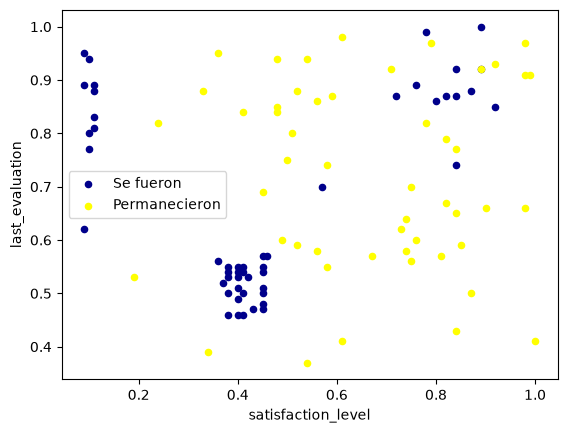

In [3]:
ax = data[data["left"] == 1][0:50].plot(kind="scatter", x="satisfaction_level"
                    , y="last_evaluation", color="DarkBlue", label="Se fueron");
ax = data[data["left"] == 0][0:50].plot(kind="scatter", x="satisfaction_level"
                    , y="last_evaluation", color="Yellow", label="Permanecieron",ax=ax);
plt.show()

In [4]:
# Pre-Procesamiento de datos y selección
data.dtypes

satisfaction_level       float64
last_evaluation          float64
number_project             int64
average_montly_hours       int64
time_spend_company         int64
Work_accident              int64
left                       int64
promotion_last_5years      int64
sales_IT                   int64
sales_RandD                int64
sales_accounting           int64
sales_hr                   int64
sales_management           int64
sales_marketing            int64
sales_product_mng          int64
sales_sales                int64
sales_support              int64
sales_technical            int64
salary_high                int64
salary_low                 int64
salary_medium              int64
dtype: object

In [5]:
feature_df = data.drop(["left"], axis=1)
X = np.asarray(feature_df)
X[0:5]

array([[3.80e-01, 5.30e-01, 2.00e+00, 1.57e+02, 3.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 1.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        1.00e+00, 0.00e+00],
       [8.00e-01, 8.60e-01, 5.00e+00, 2.62e+02, 6.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 1.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        0.00e+00, 1.00e+00],
       [1.10e-01, 8.80e-01, 7.00e+00, 2.72e+02, 4.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 1.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        0.00e+00, 1.00e+00],
       [7.20e-01, 8.70e-01, 5.00e+00, 2.23e+02, 5.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        0.00e+00, 0.00e+00, 1.00e+00, 0.00e+00, 0.00e+00, 0.00e+00,
        1.00e+00, 0.00e+00],
       [3.70e-01, 5.20e-01, 2.00e+00, 1.59e+02, 3.00e+00, 0.00e+00,


In [6]:
data["left"] = data["left"].astype("int")
y = np.asarray(data["left"])
y[0:5]

array([1, 1, 1, 1, 1])

In [7]:
# Creación de grupos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, 
                                test_size=0.2, random_state=4)
print("Grupo de entrenamiento", X_train.shape, y_train.shape)
print("Grupo de prueba", X_test.shape, y_test.shape)

Grupo de entrenamiento (11999, 20) (11999,)
Grupo de prueba (3000, 20) (3000,)


In [8]:
from sklearn import svm
clf = svm.SVC(kernel="rbf")
clf.fit(X_train, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [9]:
# Predicción para la base de prueba
yhat = clf.predict(X_test)
yhat[0:5]

array([0, 0, 0, 0, 0])

In [10]:
# Creación de matriz de confusión
from sklearn.metrics import confusion_matrix
y_pred = clf.predict(X)
cm = confusion_matrix(y_test, yhat)
cm

array([[2287,    0],
       [ 669,   44]])

In [11]:
y_test

array([0, 1, 0, ..., 0, 1, 1], shape=(3000,))

In [12]:
yhat

array([0, 0, 0, ..., 0, 0, 0], shape=(3000,))

In [13]:
z = y_test - yhat
z

array([0, 1, 0, ..., 0, 1, 1], shape=(3000,))

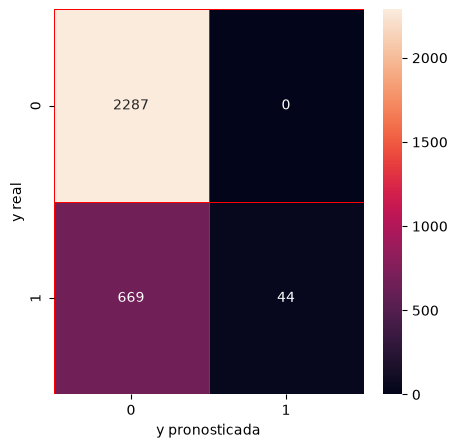

In [14]:
# Visualización de la matriz de confusión
import seaborn as sns
f, ax = plt.subplots(figsize=(5,5))

sns.heatmap(cm, annot=True, linewidths=0.5, linecolor="red", fmt=".0f", ax=ax)
plt.xlabel("y pronosticada")
plt.ylabel("y real")
plt.show()

In [15]:
#Estaditsicas de desempeño
from sklearn.metrics import classification_report
cnf_matrix = confusion_matrix(y_test, yhat, labels=[0,1])
print(classification_report(y_test, yhat))

              precision    recall  f1-score   support

           0       0.77      1.00      0.87      2287
           1       1.00      0.06      0.12       713

    accuracy                           0.78      3000
   macro avg       0.89      0.53      0.49      3000
weighted avg       0.83      0.78      0.69      3000



In [16]:
PrecisionPermanecieron = cm[0,0] / (cm[0,0] + cm[1,0])
PrecisionPermanecieron

np.float64(0.773680649526387)

In [17]:
PrecisionSeFueron = cm[1,1] / (cm[1,1] + cm[0,1])
PrecisionSeFueron

np.float64(1.0)

In [18]:
RecallPermanecieron = cm[0,0] / (cm[0,0] + cm[0,1])
RecallPermanecieron

np.float64(1.0)

In [19]:
RecallSeFueron = cm[1,1] / (cm[1,0] + cm[1,1])
RecallSeFueron

np.float64(0.061711079943899017)

In [20]:
F1Permanecieron = 2 * (PrecisionPermanecieron * RecallPermanecieron) / (PrecisionPermanecieron + RecallPermanecieron)
F1Permanecieron

np.float64(0.8724012969673851)

In [21]:
F1SeFueron = 2 * (PrecisionSeFueron * RecallSeFueron) / (PrecisionSeFueron + RecallSeFueron)
F1SeFueron

np.float64(0.11624834874504625)

In [22]:
SoportePermanecieron = cm[0,0] + cm[0,1]
SoportePermanecieron

np.int64(2287)

In [23]:
SoporteSeFueron = cm[1,0] + cm[1,1]
SoporteSeFueron

np.int64(713)

In [24]:
Correctos = cm[0,0] + cm[1,1]
Incorrectos = cm[0,1] + cm[1,0]
PrecisionGlobal = Correctos / (Correctos + Incorrectos)
PrecisionGlobal

np.float64(0.777)

In [25]:
MacroAvgPrecision = (PrecisionPermanecieron + PrecisionSeFueron) / 2
MacroAvgPrecision

np.float64(0.8868403247631935)

In [26]:
MacroAvgRecall = (RecallPermanecieron + RecallSeFueron) / 2
MacroAvgRecall

np.float64(0.5308555399719495)

In [27]:
MacroF1Score = (F1Permanecieron + F1SeFueron) / 2
MacroF1Score

np.float64(0.4943248228562157)

In [28]:
PesoPermanecieron = SoportePermanecieron / (SoportePermanecieron + SoporteSeFueron)
PesoSeFueron = SoporteSeFueron / (SoportePermanecieron + SoporteSeFueron)

In [29]:
WAvgPrecision = PrecisionPermanecieron * PesoPermanecieron + PrecisionSeFueron * PesoSeFueron
WAvgPrecision

np.float64(0.8274692151556158)

In [30]:
WAvgRecall = RecallPermanecieron * PesoPermanecieron + RecallSeFueron * PesoSeFueron
WAvgRecall

np.float64(0.777)

In [31]:
#Prueba de kernel lineal
clf = svm.SVC(kernel='linear')
clf.fit(X_train, y_train)

yhat = clf.predict(X_test)

#confusion matrix
from sklearn.metrics import confusion_matrix
y_pred = clf.predict(X)
cm = confusion_matrix(y_test, yhat)
cm

array([[2149,  138],
       [ 522,  191]])

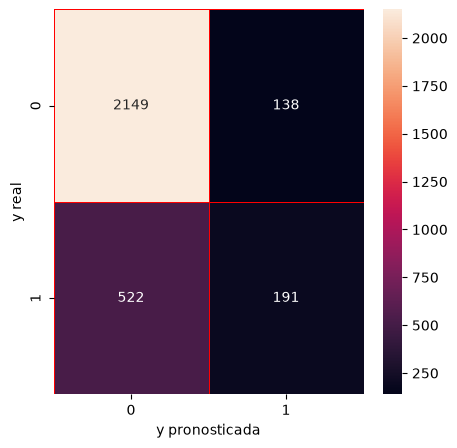

In [32]:
# Visualización de la matriz de confusión
import seaborn as sns
f, ax = plt.subplots(figsize=(5,5))

sns.heatmap(cm, annot=True, linewidths=0.5, linecolor="red", fmt=".0f", ax=ax)
plt.xlabel("y pronosticada")
plt.ylabel("y real")
plt.show()

In [33]:
from sklearn.metrics import classification_report
# import itertools

cnf_matrix = confusion_matrix(y_test, yhat, labels=[0,1])
# np.set_printoptions(precision=2)

print(classification_report(y_test, yhat))

              precision    recall  f1-score   support

           0       0.80      0.94      0.87      2287
           1       0.58      0.27      0.37       713

    accuracy                           0.78      3000
   macro avg       0.69      0.60      0.62      3000
weighted avg       0.75      0.78      0.75      3000



In [34]:
#Prueba de SVM con kernerl polinomial
clf = svm.SVC(kernel='poly')
clf.fit(X_train, y_train)

yhat = clf.predict(X_test)

#confusion matrix
from sklearn.metrics import confusion_matrix
y_pred = clf.predict(X)
cm = confusion_matrix(y_test, yhat)
cm

array([[2287,    0],
       [ 713,    0]])

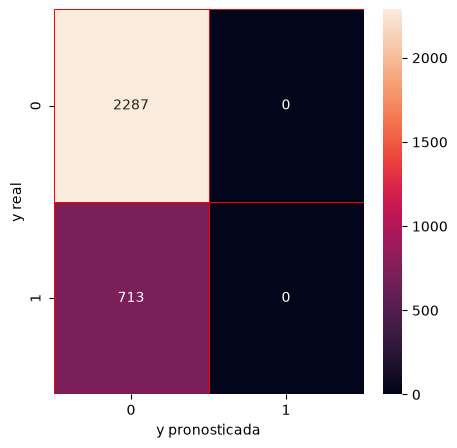

In [35]:
# Visualización de la matriz de confusión
f, ax = plt.subplots(figsize=(5,5))

sns.heatmap(cm, annot=True, linewidths=0.5, linecolor="red", fmt=".0f", ax=ax)
plt.xlabel("y pronosticada")
plt.ylabel("y real")
plt.show()

In [36]:
from sklearn.metrics import classification_report

cnf_matrix = confusion_matrix(y_test, yhat, labels=[0,1])

print(classification_report(y_test, yhat))

              precision    recall  f1-score   support

           0       0.76      1.00      0.87      2287
           1       0.00      0.00      0.00       713

    accuracy                           0.76      3000
   macro avg       0.38      0.50      0.43      3000
weighted avg       0.58      0.76      0.66      3000



In [37]:
#Prueba de kernel sigmoide
clf = svm.SVC(kernel='sigmoid')
clf.fit(X_train, y_train)

yhat = clf.predict(X_test)

#confusion matrix
from sklearn.metrics import confusion_matrix
y_pred = clf.predict(X)
cm = confusion_matrix(y_test, yhat)
cm

array([[1885,  402],
       [ 507,  206]])

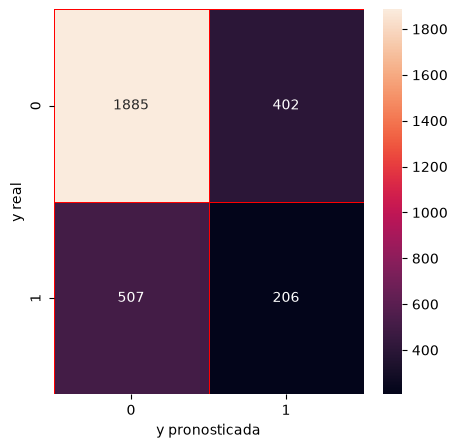

In [38]:
# Visualización de la matriz de confusión
f, ax = plt.subplots(figsize=(5,5))

sns.heatmap(cm, annot=True, linewidths=0.5, linecolor="red", fmt=".0f", ax=ax)
plt.xlabel("y pronosticada")
plt.ylabel("y real")
plt.show()

In [39]:
from sklearn.metrics import classification_report

cnf_matrix = confusion_matrix(y_test, yhat, labels=[0,1])

print(classification_report(y_test, yhat))

              precision    recall  f1-score   support

           0       0.79      0.82      0.81      2287
           1       0.34      0.29      0.31       713

    accuracy                           0.70      3000
   macro avg       0.56      0.56      0.56      3000
weighted avg       0.68      0.70      0.69      3000



In [40]:
# Modelo SVM con kernel Lineal
clf = svm.SVC(kernel='linear')
clf.fit(X_train, y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [42]:
empleado = pd.read_csv("recursos_humanos (2).csv")
empleado

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.87,1,5,242,5,0,1,0,sales,low


In [43]:
empleado = empleado.reindex(columns=feature_df.columns, fill_value=0)

X_empleado = np.asarray(empleado)
X_empleado

array([[  0.87,   1.  ,   5.  , 242.  ,   5.  ,   0.  ,   0.  ,   0.  ,
          0.  ,   0.  ,   0.  ,   0.  ,   0.  ,   0.  ,   0.  ,   0.  ,
          0.  ,   0.  ,   0.  ,   0.  ]])

In [44]:
# Predicción para el empleado
pronostico = clf.predict(X_empleado)
pronostico

array([0])